# From Hodgkin–Huxley to a channelopathy: writing your own neuron in NESTML

**Goals**
1. Explore the classic Hodgkin–Huxley (HH) neuron built into NEST.
2. Re-create the same neuron in NESTML, generate code for it, and check that it behaves identically.
3. **Edit the NESTML file** to add a disease-causing sodium-channel mutation, regenerate, and compare wild type vs. mutant.

**Kernel:** on EBRAINS JupyterLab choose the most recent *EBRAINS-xx.xx* kernel (it ships NEST + NESTML).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import nest
import pynestml
from pynestml.codegeneration.nest_code_generator_utils import NESTCodeGeneratorUtils

print("NEST  :", nest.__version__)
print("NESTML:", pynestml.__version__)


              -- N E S T --
  Copyright (C) 2004 The NEST Initiative

 Version: 3.9.0
 Built: Apr 14 2026 11:46:17

 This program is provided AS IS and comes with
 NO WARRANTY. See the file LICENSE for details.

 Problems or suggestions?
   Visit https://www.nest-simulator.org

 Type 'nest.help()' to find out more about NEST.

NEST  : 3.9.0
NESTML: 8.2.0


---
# Part 1 – Play with the built-in HH neuron (`hh_psc_alpha`)

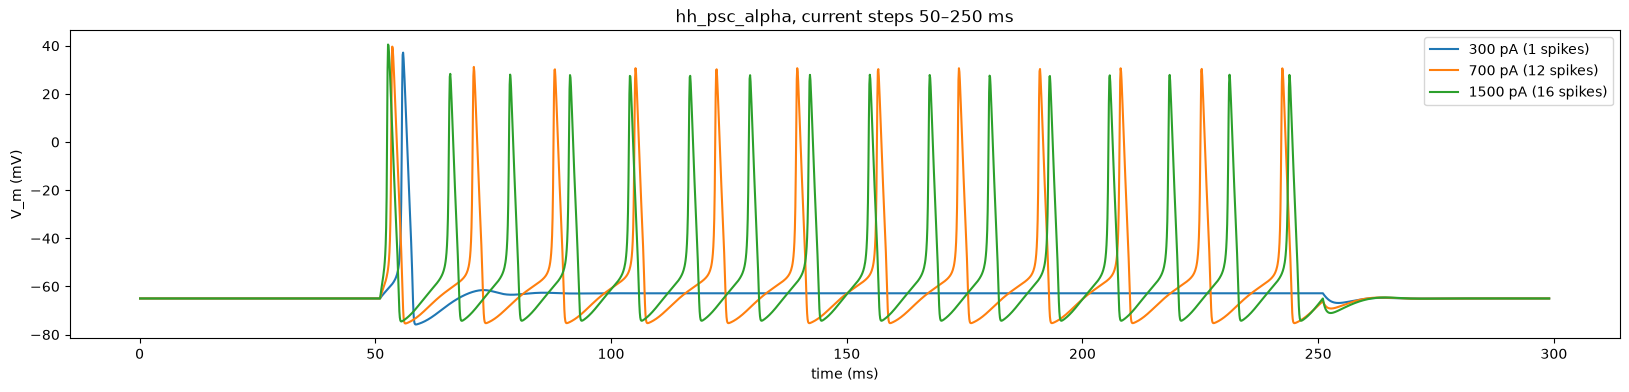

In [2]:
plt.figure(figsize=(20, 4))
for amp in [300., 700., 1500.]:

    nest.ResetKernel()
    nest.set_verbosity("M_WARNING")
    
    n = nest.Create("hh_psc_alpha")

    stim = nest.Create("step_current_generator",
                       params={"amplitude_times": [50., 250.], "amplitude_values": [amp, 0.]})
    
    vm = nest.Create("voltmeter", params={"interval": 0.1})
    sr = nest.Create("spike_recorder")

    nest.Connect(stim, n)
    nest.Connect(vm, n)
    nest.Connect(n, sr)

    nest.Simulate(300.0)

    t = vm.get("events")["times"]
    V = vm.get("events")["V_m"]
    spk = sr.get("events")["times"]

    plt.plot(t, V, label=f"{amp:.0f} pA ({len(spk)} spikes)")

plt.xlabel("time (ms)")
plt.ylabel("V_m (mV)")
plt.legend()
plt.title("hh_psc_alpha, current steps 50–250 ms")
plt.show()

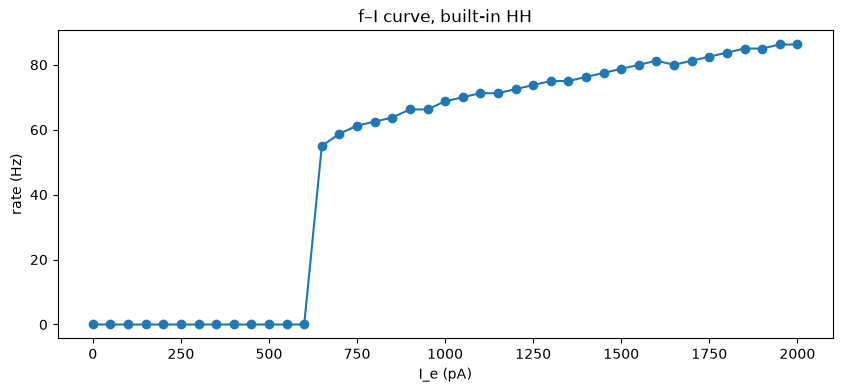

In [3]:
currents = np.arange(0., 2001., 50.)
t_sim, t_discard = 1000., 200.

nest.ResetKernel()
nest.set_verbosity("M_WARNING")

pop = nest.Create("hh_psc_alpha", len(currents))
pop.I_e = list(currents)

sr = nest.Create("spike_recorder")

nest.Connect(pop, sr)

nest.Simulate(t_sim)

senders = sr.get("events")["senders"]
times = sr.get("events")["times"]
rate_builtin = [np.sum((senders == gid) & (times > t_discard)) / ((t_sim - t_discard) / 1000.)
                for gid in pop.tolist()]

plt.figure(figsize=(10, 4))
plt.plot(currents, rate_builtin, "o-")
plt.xlabel("I_e (pA)")
plt.ylabel("rate (Hz)")
plt.title("f–I curve, built-in HH")
plt.show()

**Questions (Part 1)**
- What is the minimal current that produces repetitive firing (rheobase)? Is the onset of firing continuous (type I) or abrupt (type II)?
- Change `g_K` or `g_Na` via `params={...}` and describe what happens.

---
# Part 2 – The same neuron written in NESTML

The next cell writes the model to the file **`hh_psc_alpha_neuron.nestml`** (you'll see it appear in the file browser on the left). Open the NESTML file and read it carefully: the `equations` block contains exactly the HH equations you know from the lecture.

In [4]:
# Generate C++ code, compile it and load it into NEST (takes ~1 minute)

wt_module, wt_model = NESTCodeGeneratorUtils.generate_code_for(open("hh_psc_alpha_neuron.nestml").read())


              -- N E S T --
  Copyright (C) 2004 The NEST Initiative

 Version: 3.9.0
 Built: Apr 14 2026 11:46:17

 This program is provided AS IS and comes with
 NO WARRANTY. See the file LICENSE for details.

 Problems or suggestions?
   Visit https://www.nest-simulator.org

 Type 'nest.help()' to find out more about NEST.



**Sanity check:** the NESTML neuron must behave like the built-in one.

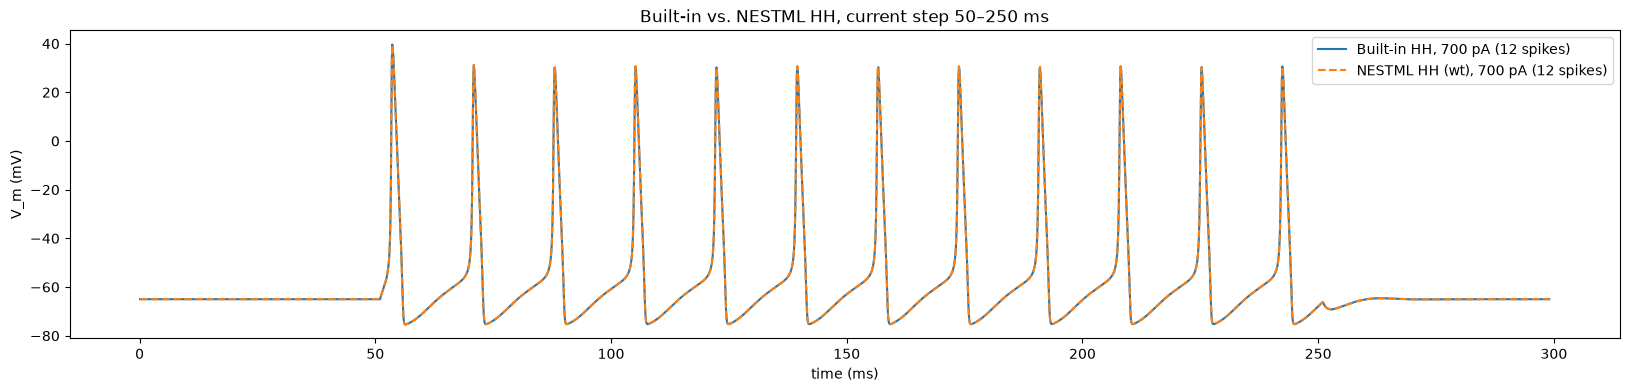

In [5]:
amp = 700.

plt.figure(figsize=(20, 4))

nest.ResetKernel()
nest.set_verbosity("M_WARNING")
nest.Install(wt_module)

n = nest.Create("hh_psc_alpha")
wt = nest.Create(wt_model)

stim = nest.Create("step_current_generator",
                   params={"amplitude_times": [50., 250.], "amplitude_values": [amp, 0.]})
vm = nest.Create("voltmeter", params={"interval": 0.1})
sr = nest.Create("spike_recorder")

nest.Connect(stim, n); nest.Connect(stim, wt)
nest.Connect(vm, n); nest.Connect(vm, wt)
nest.Connect(n, sr); nest.Connect(wt, sr)

nest.Simulate(300.0)

ev = vm.get("events")
spk = sr.get("events")

# the voltmeter records both neurons: separate them by sender id
for neuron, name, style in [(n, "Built-in HH", "-"), (wt, "NESTML HH (wt)", "--")]:
    gid = neuron.global_id
    sel = ev["senders"] == gid
    n_spk = sum(spk["senders"] == gid)
    plt.plot(ev["times"][sel], ev["V_m"][sel], style, label=f"{name}, {amp:.0f} pA ({n_spk} spikes)")
    
plt.xlabel("time (ms)")
plt.ylabel("V_m (mV)")
plt.legend()
plt.title("Built-in vs. NESTML HH, current step 50–250 ms")
plt.show()

---
# Part 3 – Your task: model a sodium channelopathy

Many inherited diseases (some epilepsies, paramyotonia congenita, long-QT syndrome type 3, hyperkalemic periodic paralysis) are caused by mutations in voltage-gated **Na⁺ channels** that impair **fast inactivation**: the mutant channel opens normally, but does not close again.

**Extremely simplified model:** a fraction `p_mut` of all Na⁺ channels is mutant and has *no h gate*:

$$I_{Na,WT} = (1-p_{mut})\,\bar g_{Na}\, m^3 h\,(V-E_{Na}) \qquad I_{Na,mut} = p_{mut}\,\bar g_{Na}\, m^3\,(V-E_{Na})$$

Run the next cell: it creates **`hh_mut_neuron.nestml`**, a copy of the wild-type file. Then **open `hh_mut_neuron.nestml` in the JupyterLab editor** (double-click it in the file browser) and:

1. Add a new parameter `p_mut real = 0.02` in the `parameters` block.
2. Multiply the existing `I_Na` by `(1 - p_mut)`.
3. Add a new inline equation for the mutant channels (it has no `Inact_h`!): `inline I_NaMut pA = p_mut * g_Na * Act_m**3 * (V_m - E_Na)`
4. Add `I_NaMut` to the membrane equation `V_m'`.
5. Save the file (Ctrl+S).

*Hint:* units must be consistent – `I_NaMut` is in `pA`, like `I_Na`. NESTML will tell you if they are not.

In [6]:
# After editing and saving the file: generate and load the mutant model

mut_module, mut_model = NESTCodeGeneratorUtils.generate_code_for(open("hh_psc_alpha_neuron_mut.nestml").read())


              -- N E S T --
  Copyright (C) 2004 The NEST Initiative

 Version: 3.9.0
 Built: Apr 14 2026 11:46:17

 This program is provided AS IS and comes with
 NO WARRANTY. See the file LICENSE for details.

 Problems or suggestions?
   Visit https://www.nest-simulator.org

 Type 'nest.help()' to find out more about NEST.



---
# Part 4 – Wild type vs. mutant

Because `p_mut` is a *parameter*, we can change it from Python without regenerating code.

**Check 1:** with `p_mut = 0` the mutant model must be identical to the wild type. Why?

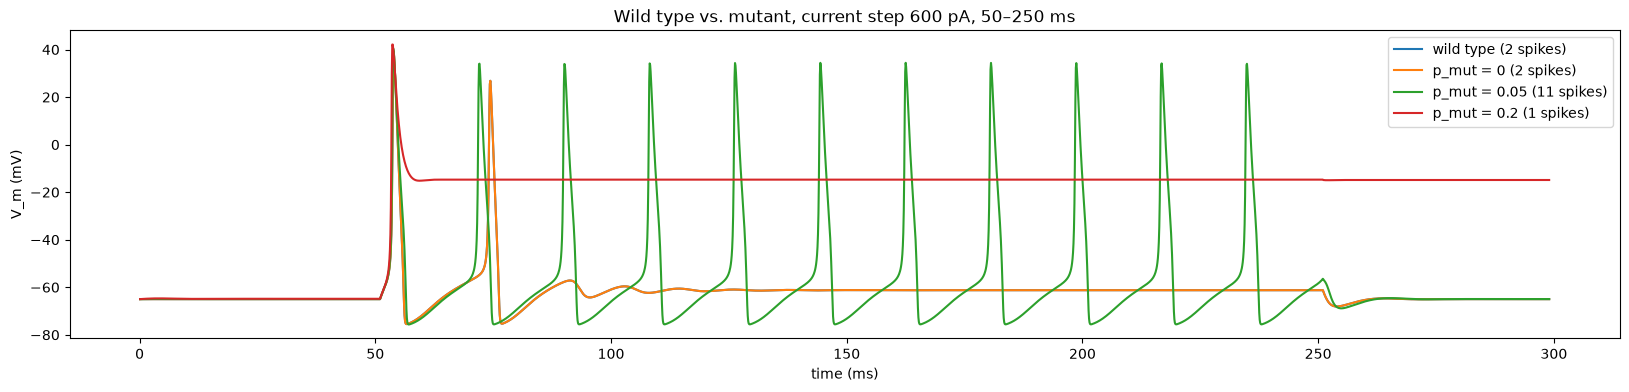

In [7]:
amp = 600.

plt.figure(figsize=(20, 4))


for module, model, params, name in [(wt_module, wt_model,  {},              "wild type"),
                                    (mut_module, mut_model, {"p_mut": 0.0},  "p_mut = 0"),
                                    (mut_module, mut_model, {"p_mut": 0.05}, "p_mut = 0.05"),
                                    (mut_module, mut_model, {"p_mut": 0.2},  "p_mut = 0.2")]:
    
    nest.ResetKernel()
    nest.set_verbosity("M_WARNING")
    nest.Install(module)
    
    n = nest.Create(model, params=params)

    stim = nest.Create("step_current_generator",
                       params={"amplitude_times": [50., 250.], "amplitude_values": [amp, 0.]})
    vm = nest.Create("voltmeter", params={"interval": 0.1})
    sr = nest.Create("spike_recorder")

    nest.Connect(stim, n)
    nest.Connect(vm, n)
    nest.Connect(n, sr)

    nest.Simulate(300.0)

    t = vm.get("events")["times"]
    V = vm.get("events")["V_m"]
    spk = sr.get("events")["times"]

    plt.plot(t, V, label=f"{name} ({len(spk)} spikes)")

plt.xlabel("time (ms)")
plt.ylabel("V_m (mV)")
plt.legend()
plt.title(f"Wild type vs. mutant, current step {amp:.0f} pA, 50–250 ms")
plt.show()

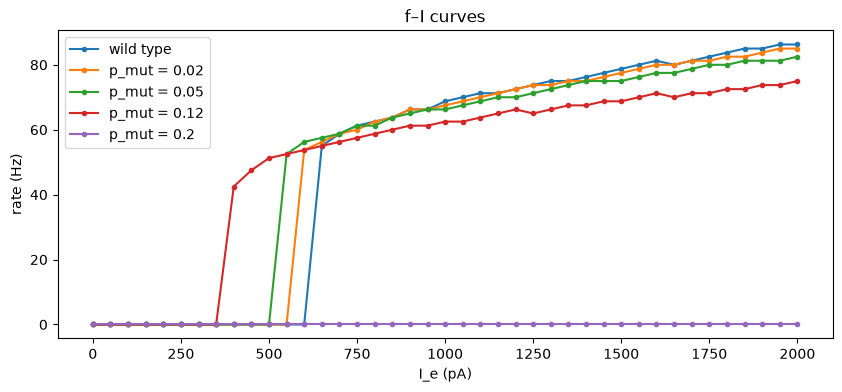

In [8]:
currents = np.arange(0., 2001., 50.)
t_sim, t_discard = 1000., 200.

plt.figure(figsize=(10, 4))

for module, model, params, name in [(wt_module,  wt_model,  {},               "wild type"),
                                    (mut_module, mut_model, {"p_mut": 0.02},  "p_mut = 0.02"),
                                    (mut_module, mut_model, {"p_mut": 0.05},  "p_mut = 0.05"),
                                    (mut_module, mut_model, {"p_mut": 0.12},  "p_mut = 0.12"),
                                    (mut_module, mut_model, {"p_mut": 0.2},   "p_mut = 0.2")]:
    
    nest.ResetKernel()
    nest.set_verbosity("M_WARNING")
    nest.Install(module)

    pop = nest.Create(model, len(currents), params=params)
    pop.I_e = list(currents)

    sr = nest.Create("spike_recorder")

    nest.Connect(pop, sr)

    nest.Simulate(t_sim)

    senders = sr.get("events")["senders"]
    times = sr.get("events")["times"]
    rates = [np.sum((senders == gid) & (times > t_discard)) / ((t_sim - t_discard) / 1000.)
             for gid in pop.tolist()]

    plt.plot(currents, rates, "o-", ms=3, label=name)

plt.xlabel("I_e (pA)")
plt.ylabel("rate (Hz)")
plt.legend()
plt.title("f–I curves")
plt.show()

**Questions (Part 4)**
- At which `p_mut` does the f–I curve start to differ from the wild type? Which part of the curve changes first?
- What happens to the neuron for large `p_mut` and large currents? Look at the voltage traces.

---
# Part 5 – Experimental protocol 1: current-clamp steps (Wang et al. 1998, Fig. 1)

From now on we use the neuron like an experimentalist would, with the protocols of **Wang et al. (1998)**, *J Physiol* 509:183 (`docs/REF2`).

**Protocol (Fig. 1):** whole-cell current clamp, starting from rest; current steps from **−50 to +150 pA in 50 pA increments**; for the V–I curve (Fig. 1D) V is measured **145 ms into the pulse**. The step duration is not stated; we use 200 ms.

## 5a – The current steps (Fig. 1A)

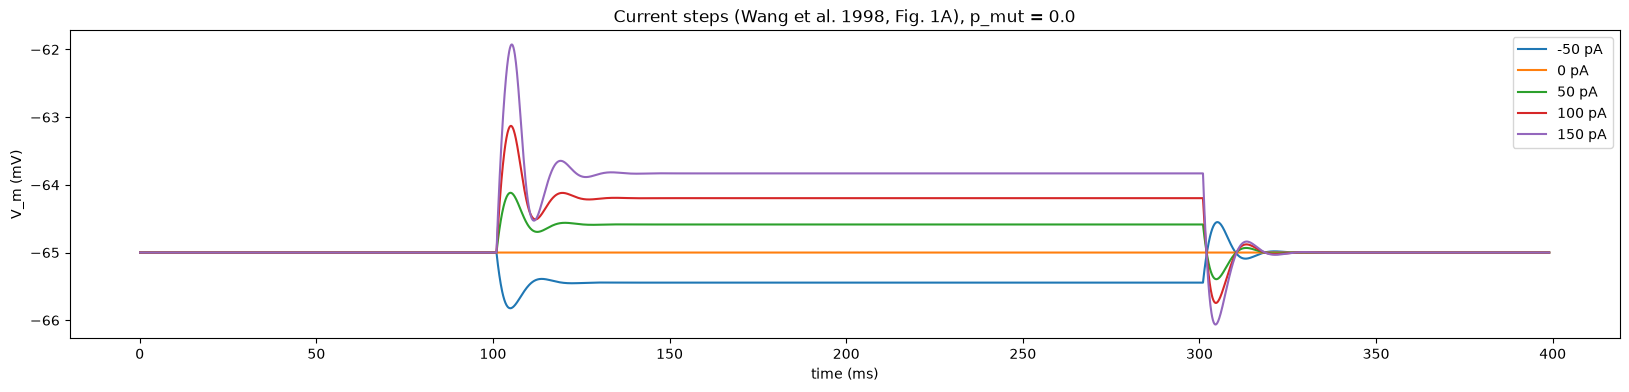

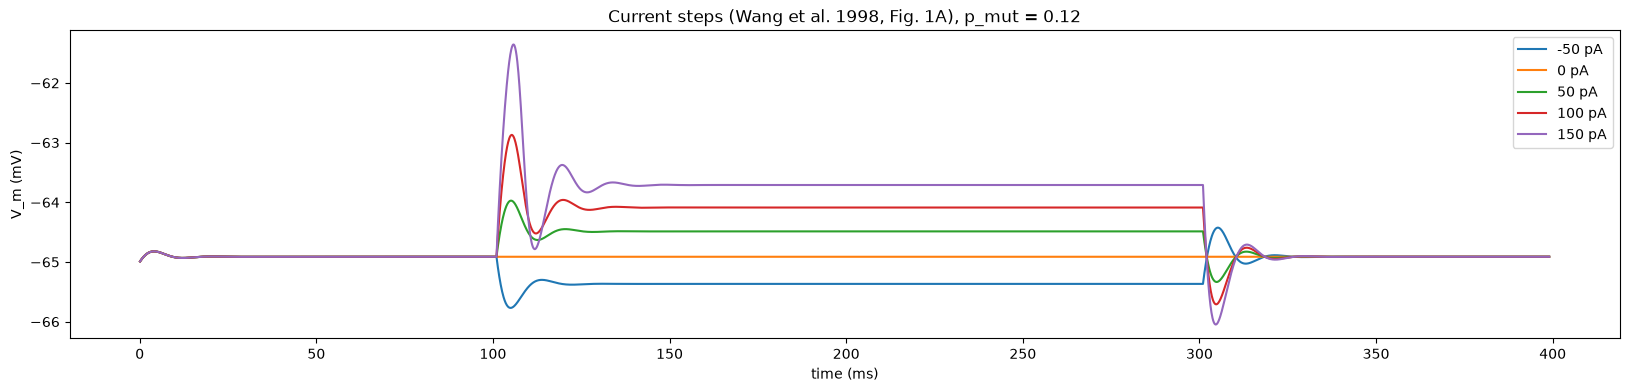

In [9]:
currents = np.arange(-50., 151., 50.)   # pA: -50 to 150 pA in 50 pA increments
t_on, t_step = 100., 200.               # ms: the step starts at t_on and lasts t_step
t_sim = t_on + t_step + 100.

for p in [0.0, 0.12]:                   # 0 = wild type

    plt.figure(figsize=(20, 4))

    for amp in currents:

        nest.ResetKernel()
        nest.set_verbosity("M_WARNING")
        nest.Install(mut_module)

        n = nest.Create(mut_model, params={"p_mut": p})

        stim = nest.Create("step_current_generator",
                           params={"amplitude_times": [t_on, t_on + t_step], "amplitude_values": [amp, 0.]})
        vm = nest.Create("voltmeter", params={"interval": 0.1})

        nest.Connect(stim, n)
        nest.Connect(vm, n)

        nest.Simulate(t_sim)

        plt.plot(vm.get("events")["times"], vm.get("events")["V_m"], label=f"{amp:.0f} pA")

    plt.xlabel("time (ms)")
    plt.ylabel("V_m (mV)")
    plt.legend()
    plt.title(f"Current steps (Wang et al. 1998, Fig. 1A), p_mut = {p}")
    plt.show()

**Questions (5a)**
- Does the wild-type HH neuron spike with the paper's current steps? The MNTB neuron fires 1–3 spikes for steps above 100 pA.
- Extend `currents` until you find, for the wild type, (i) the smallest step that gives **one** spike and (ii) the smallest step that gives **repetitive** firing. Is there a range where the HH neuron fires only at the step onset, like the MNTB neuron?
- The paper describes "an initial small hump which decayed back to a steady state" for subthreshold steps. Do you see it in the HH traces?
- Repeat with the mutant. Which of your two thresholds changes, and in which direction?

## 5b – The V–I curve (Fig. 1D)

For each step we stop the simulation exactly 145 ms into the pulse and read V_m directly from the neuron.

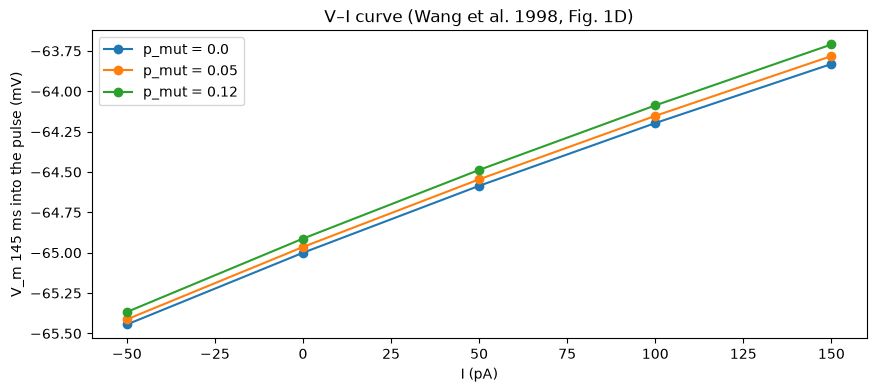

In [10]:
currents = np.arange(-50., 151., 50.)   # pA, as in Fig. 1A
t_on, t_step = 100., 200.               # ms
t_read = 145.                           # ms into the pulse (Fig. 1D)

plt.figure(figsize=(10, 4))

for p in [0.0, 0.05, 0.12]:

    V_read = []

    for amp in currents:

        nest.ResetKernel()
        nest.set_verbosity("M_WARNING")
        nest.Install(mut_module)

        n = nest.Create(mut_model, params={"p_mut": p})

        stim = nest.Create("step_current_generator",
                           params={"amplitude_times": [t_on, t_on + t_step], "amplitude_values": [amp, 0.]})
        nest.Connect(stim, n)

        nest.Simulate(t_on + t_read)    # stop 145 ms into the pulse
        V_read.append(n.V_m)

    plt.plot(currents, V_read, "o-", label=f"p_mut = {p}")

plt.xlabel("I (pA)")
plt.ylabel("V_m 145 ms into the pulse (mV)")
plt.legend()
plt.title("V–I curve (Wang et al. 1998, Fig. 1D)")
plt.show()

**Questions (5b)**
- Use the points at −50 and +50 pA to compute the **input resistance** R_in = ΔV/ΔI (mV/nA = MΩ) of the wild type. Do the same from Fig. 1D of the paper. Which neuron has the larger R_in, and what does that mean for the size of the current steps you need?
- Fig. 1D shows strong **outward rectification** above rest. Does the HH curve rectify? Does the mutant curve bend in the same or in the opposite direction? Why?
- How much does `p_mut` change the resting potential (the point at 0 pA) and the rest of the curve?

---
# Part 6 – Experimental protocol 2: voltage-clamp steps (Wang et al. 1998, Fig. 2)

**Protocol (Fig. 2A–B):** whole-cell voltage clamp with **TTX** in the bath; holding potential **−80 mV**; each step is preceded by a **30 ms prepulse to −100 mV**; **200 ms** steps from **−80 to +60 mV in 20 mV increments**; the I–V curve is measured **195 ms into the pulse**.

## Add a voltage clamp to the mutant model

NEST has no voltage-clamp device, so we build an ideal one into the model: when `clamp_on = 1` the derivative of V_m is zero, V_m stays where we put it from Python, and the gating variables keep evolving exactly as in an experiment. Open **`hh_psc_alpha_neuron_mut.nestml`** again and:

1. Add a new parameter `clamp_on real = 0` (1 = voltage clamp on, 0 = off).
2. Multiply the **whole right-hand side** of `V_m'` by `(1 - clamp_on)`. Watch the parentheses.
3. NEST records only state variables by default. Write the keyword `recordable` in front of `inline I_Na`, `inline I_NaMut`, `inline I_K` and `inline I_L` (e.g. `recordable inline I_K pA = ...`).
4. Save the file (Ctrl+S) and run the next cell.

With `clamp_on = 0` (the default) the model behaves exactly as before, so Parts 4 and 5 are unchanged.

In [11]:
mut_module, mut_model = NESTCodeGeneratorUtils.generate_code_for(open("hh_psc_alpha_neuron_mut.nestml").read())

nest.ResetKernel()
nest.Install(mut_module)
print(nest.GetDefaults(mut_model)["recordables"])   # I_Na, I_NaMut, I_K and I_L must appear here


              -- N E S T --
  Copyright (C) 2004 The NEST Initiative

 Version: 3.9.0
 Built: Apr 14 2026 11:46:17

 This program is provided AS IS and comes with
 NO WARRANTY. See the file LICENSE for details.

 Problems or suggestions?
   Visit https://www.nest-simulator.org

 Type 'nest.help()' to find out more about NEST.



('Act_m', 'Act_n', 'Inact_h', 'V_m', 'V_m_old', 'refr_t', 'K_syn_exc__X__exc_spikes', 'K_syn_exc__X__exc_spikes__d', 'K_syn_inh__X__inh_spikes', 'K_syn_inh__X__inh_spikes__d', 'I_Na', 'I_NaMut', 'I_K', 'I_L')


**How the clamp is used:** we create the neuron with `clamp_on = 1` and set `n.V_m` from Python before each `nest.Simulate()`. Each `Simulate()` call is one segment of the protocol (holding → prepulse → step → back to holding).

**Technical note:** the HH rate functions α_m and α_n have the form x / (1 − exp(−x/10)), which is 0/0 exactly at V = −40 mV and V = −55 mV. Commanding exactly −40.0 mV gives `nan`. We add 0.001 mV to every command value. (Try removing it once to see what happens.)

## 6a – The paper's protocol: Na⁺ channels blocked (Fig. 2A–B)

Wang et al. blocked Na⁺ channels with TTX because they wanted to study K⁺ currents. In the model, TTX is `g_Na = 0`. Since our mutant current is also proportional to `g_Na`, TTX blocks the mutant channels too.

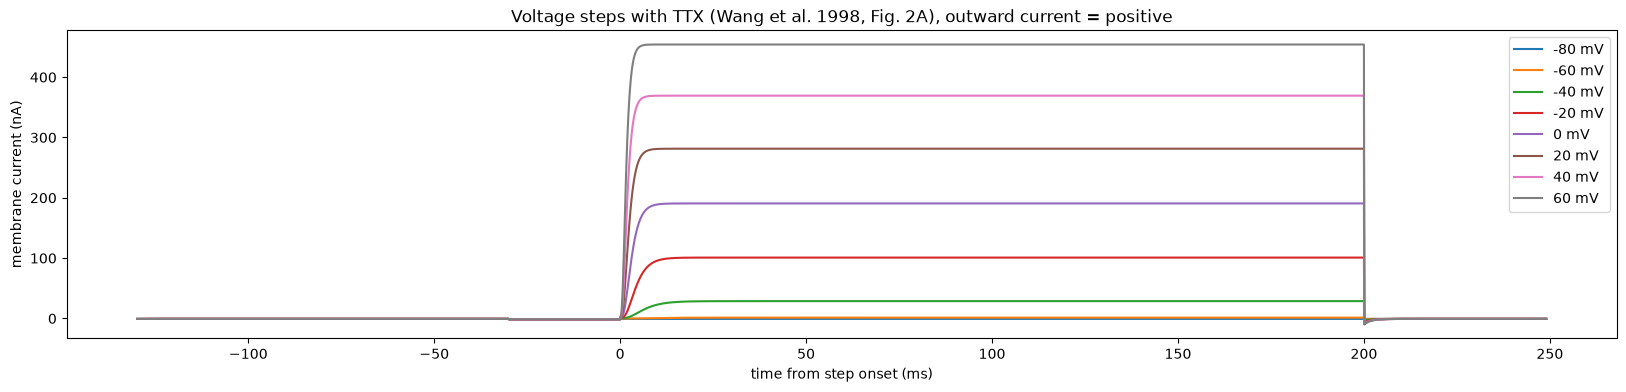

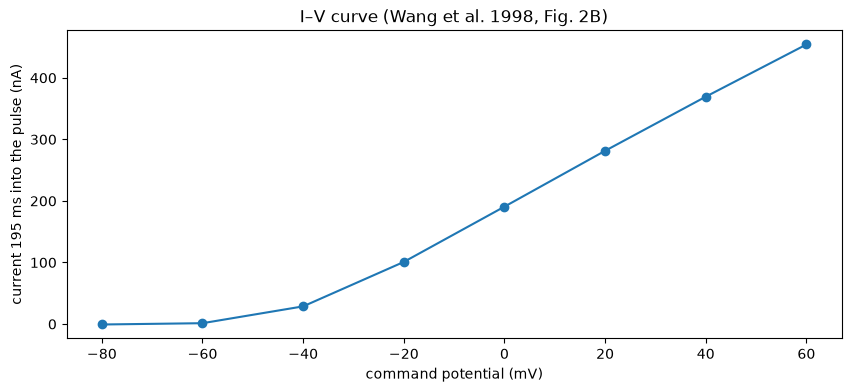

In [12]:
V_hold, V_pre = -80., -100.                    # mV: holding potential and prepulse
t_hold, t_pre, t_step, t_tail = 100., 30., 200., 50.   # ms
V_steps = np.arange(-80., 61., 20.)            # mV: -80 to +60 mV in 20 mV increments
t_read = 195.                                  # ms into the pulse (Fig. 2B)

I_read = []

plt.figure(figsize=(20, 4))

for V_step in V_steps:

    nest.ResetKernel()
    nest.set_verbosity("M_WARNING")
    nest.Install(mut_module)

    n = nest.Create(mut_model, params={"clamp_on": 1.0, "g_Na": 0.})   # g_Na = 0 mimics TTX
    mm = nest.Create("multimeter", params={"interval": 0.1, "record_from": ["I_Na", "I_NaMut", "I_K", "I_L"]})
    nest.Connect(mm, n)

    n.V_m = V_hold + 0.001
    nest.Simulate(t_hold)
    n.V_m = V_pre + 0.001
    nest.Simulate(t_pre)
    n.V_m = V_step + 0.001
    nest.Simulate(t_step)
    n.V_m = V_hold + 0.001
    nest.Simulate(t_tail)

    ev = mm.get("events")
    t = ev["times"] - t_hold - t_pre                                   # time from step onset
    I = (ev["I_Na"] + ev["I_NaMut"] + ev["I_K"] + ev["I_L"]) / 1000.   # pA -> nA

    plt.plot(t, I, label=f"{V_step:.0f} mV")
    I_read.append(I[np.argmin(np.abs(t - t_read))])

plt.xlabel("time from step onset (ms)")
plt.ylabel("membrane current (nA)")
plt.legend()
plt.title("Voltage steps with TTX (Wang et al. 1998, Fig. 2A), outward current = positive")
plt.show()

plt.figure(figsize=(10, 4))
plt.plot(V_steps, I_read, "o-")
plt.xlabel("command potential (mV)")
plt.ylabel("current 195 ms into the pulse (nA)")
plt.title("I–V curve (Wang et al. 1998, Fig. 2B)")
plt.show()

**Questions (6a)**
- Compare the HH traces and I–V curve with Fig. 2A–B. Where does the outward current start to activate? Does it inactivate during the step?
- The MNTB K⁺ current is ~15 nA at +60 mV. What is it in the HH neuron? Which parameter sets the amplitude?
- Set `V_hold = -40.` (and `t_hold = 500.`, `V_pre = V_hold`). In the MNTB neuron part of the K⁺ current disappears (Fig. 2C). Does it in the HH neuron? Look at which gating variables `I_K` contains.
- Why would changing `p_mut` here change nothing?

## 6b – The same protocol for *our* question: Na⁺ channels not blocked

Which current you isolate depends on the question. Wang et al. studied K⁺ channels, so they blocked Na⁺ channels. Our mutation is in the Na⁺ channel, so we must **not** use TTX. Instead, we block the K⁺ channels (`g_K = 0`) and look at the Na⁺ currents.

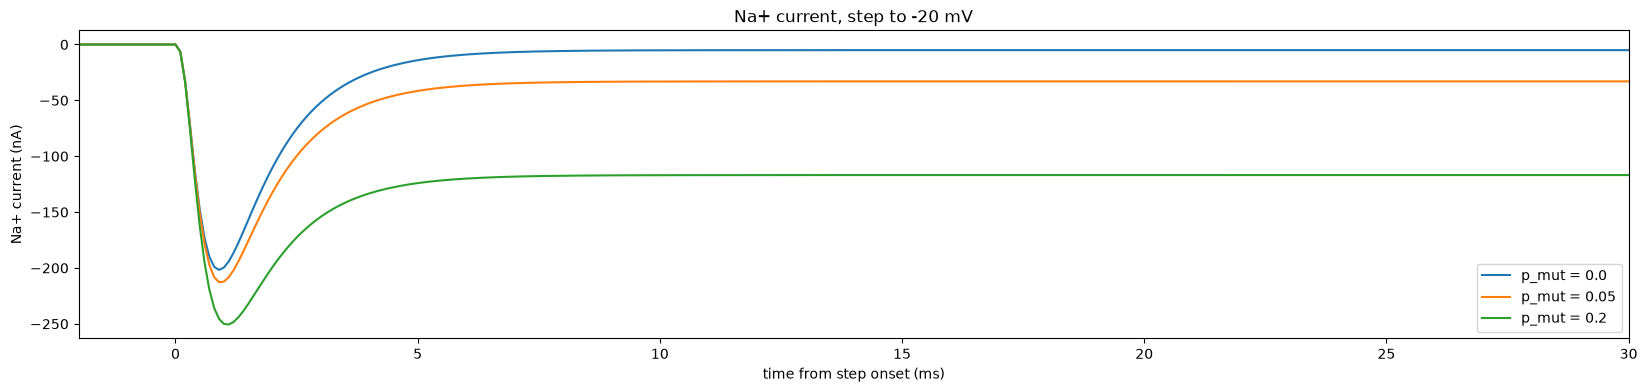

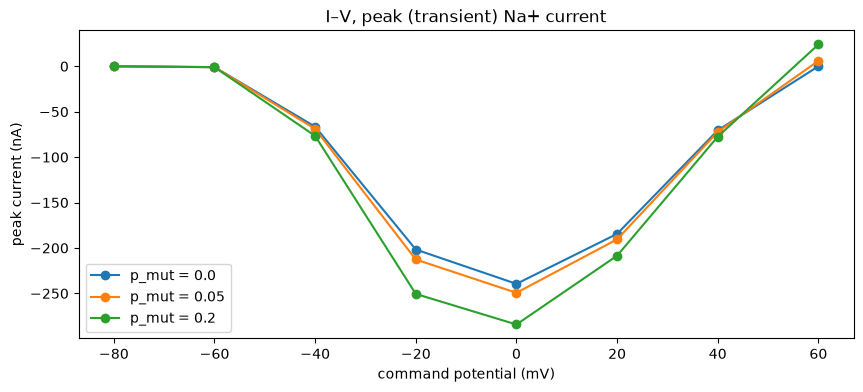

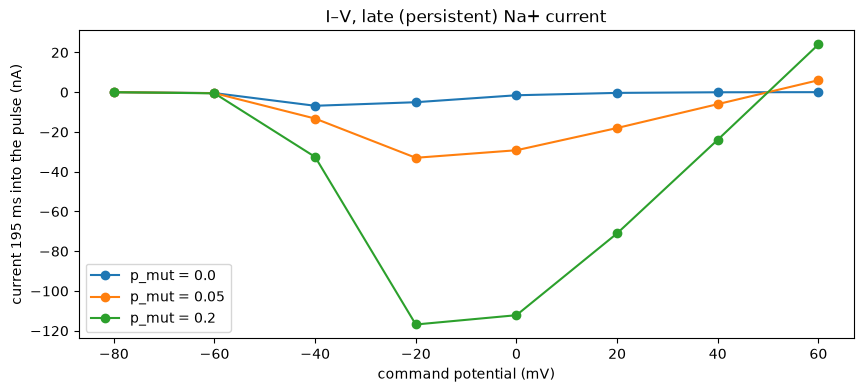

In [13]:
V_hold, V_pre = -80., -100.                    # mV
t_hold, t_pre, t_step, t_tail = 100., 30., 200., 50.   # ms
V_steps = np.arange(-80., 61., 20.)            # mV
t_read = 195.                                  # ms into the pulse (late, "persistent" current)

plt.figure(figsize=(20, 4))      # Na+ current during the step to -20 mV
I_peak, I_late = {}, {}

for p in [0.0, 0.05, 0.2]:

    I_peak[p], I_late[p] = [], []

    for V_step in V_steps:

        nest.ResetKernel()
        nest.set_verbosity("M_WARNING")
        nest.Install(mut_module)

        n = nest.Create(mut_model, params={"clamp_on": 1.0, "p_mut": p, "g_K": 0.})   # g_K = 0 blocks K+
        mm = nest.Create("multimeter", params={"interval": 0.1, "record_from": ["I_Na", "I_NaMut"]})
        nest.Connect(mm, n)

        n.V_m = V_hold + 0.001
        nest.Simulate(t_hold)
        n.V_m = V_pre + 0.001
        nest.Simulate(t_pre)
        n.V_m = V_step + 0.001
        nest.Simulate(t_step)
        n.V_m = V_hold + 0.001
        nest.Simulate(t_tail)

        ev = mm.get("events")
        t = ev["times"] - t_hold - t_pre                 # time from step onset
        I = (ev["I_Na"] + ev["I_NaMut"]) / 1000.         # nA

        I_peak[p].append(I[(t > 0) & (t <= t_step)].min())   # inward = negative
        I_late[p].append(I[np.argmin(np.abs(t - t_read))])

        if V_step == -20.:
            plt.plot(t, I, label=f"p_mut = {p}")

plt.xlim(-2., 30.)
plt.xlabel("time from step onset (ms)")
plt.ylabel("Na+ current (nA)")
plt.legend()
plt.title("Na+ current, step to -20 mV")
plt.show()

plt.figure(figsize=(10, 4))
for p in I_peak:
    plt.plot(V_steps, I_peak[p], "o-", label=f"p_mut = {p}")
plt.xlabel("command potential (mV)")
plt.ylabel("peak current (nA)")
plt.legend()
plt.title("I–V, peak (transient) Na+ current")
plt.show()

plt.figure(figsize=(10, 4))
for p in I_late:
    plt.plot(V_steps, I_late[p], "o-", label=f"p_mut = {p}")
plt.xlabel("command potential (mV)")
plt.ylabel("current 195 ms into the pulse (nA)")
plt.legend()
plt.title("I–V, late (persistent) Na+ current")
plt.show()

**Questions (6b)**
- Describe the wild-type Na⁺ current during the step to −20 mV: how fast does it activate, and what happens after a few ms? Which gate is responsible?
- What changes with `p_mut > 0`? Is the **peak** current or the **late** current more sensitive to the mutation? Which of the two I–V curves would you show to convince someone that inactivation is impaired?
- Holding at −40 mV inactivates the wild-type Na⁺ channels. Predict what happens to the mutant channels, then test it (`V_hold = -40.`, `t_hold = 500.`, `V_pre = V_hold`).
- Use the late I–V curve to explain what you saw in Part 5: why does the mutation barely change the resting potential, but lowers the current needed to fire? What happens near −20 mV, and how does that relate to the silent neuron at `p_mut = 0.2` in the f–I curve of Part 4?

---
# Summary: the strategy

You have now simulated both experimental protocols of Wang et al. 1998 on a model neuron. Write down, in a few lines, the steps you followed. For example: read the protocol from the figure legend, translate drugs into parameters, check the edited model against the original, choose which current to isolate, compare with the paper's numbers. You will need exactly these steps in your project.